## <b>주제: 초해상도(Super-Resolution) 2부</b>
------------------------

### <b>주제 설명</b>

* <b>초해상도(super-resolution)</b>는 저화질의 영상을 고화질의 영상으로 변환하는 기술을 의미합니다. 본 초해상도 강의는 총 2부로 구성되며, 오늘 공부하는 2부에서는 SRGAN을 활용하여 자연 이미지의 해상도를 개선하는 방법을 학습합니다. SRGAN을 이용하면 지각적으로(perceptually) 자연스러운 해상도 복원을 결과를 생성할 수 있습니다.

* 본 강의에서는 다음의 내용을 학습하게 됩니다.
    * SRGAN 아키텍처(architecture)
    * PyTorch를 활용한 SRGAN 구현 방법
    * SRGAN을 활용한 초해상도 기법 사용 방법

### <b>실습 가이드</b>

1. 본 실습은 GPU 자원을 사용하므로 <b>[런타임] - [런타임 유형 변경] - [GPU]</b>을 설정합니다.
2. 데이터를 깃허브(GitHub)에서 다운로드하여 Google Colab에 불러옵니다.
3. 필요한 라이브러리를 불러와 코드를 작성합니다.
4. 코드는 위에서부터 아래로 순서대로 실행합니다.

### <b>SRGAN 아키텍처 소개</b>

* [SRGAN 논문(CVPR 2017)](https://arxiv.org/abs/1609.04802)에서 상세한 아키텍처를 확인할 수 있습니다.

### <b>데이터 소개</b>

* 본 실습에서는 [Scene Classification 데이터셋](https://github.com/ndb796/Scene-Classification-Dataset)을 사용합니다.
    * 참고: [원본 Kaggle 데이터셋 링크](https://www.kaggle.com/nitishabharathi/scene-classification)
    * 본 데이터셋은 <b>저작권이 없는(No Copyright)</b> [CC0: Public Domain](https://creativecommons.org/publicdomain/zero/1.0/) 라이센스를 따라므로, 자유롭게 변형할 수 있습니다.

### <b>문제 구성</b>

* Google Colab에서 좌측의 <b>[목차]</b> 버튼을 눌러 확인할 수 있습니다.

* <b>Step 1.</b> SRGAN 아키텍처 핵심 정리
        - (이론) SRGAN 개요
        - (이론) SRGAN의 기여점(Contribution)
        - (이론) Adversarial Network Architecture
        - (이론) 목적 함수(Objective Function)

* <b>Step 2.</b> SRGAN을 활용한 초해상도(Super-Resolution) 실습
        - 핵심 아이디어 설명
        - 문제 1. 학습용 데이터셋 다운로드
        - 문제 2. VGG 특징 추출기(Feature Extractor) 구현하기
        - 문제 3. 잔여 블록(Residual Block) 구현하기
        - 문제 4. 생성자(Generator) 구현하기
        - 문제 5. 판별자(Discriminator) 구현하기
        - 문제 6. 이미지 데이터셋 클래스 구현하기
        - 문제 7. 학습을 위한 하이퍼 파라미터 구성하기
        - 문제 8. 네트워크 객체 초기화
        - 문제 9. 네트워크 학습 진행하기

### <b>최종 목표</b>
    - 초해상도(Super-Resolution) 연구 동향에 대한 이해
    - SRGAN 아키텍처 및 모델 학습 방법에 대한 이해

### <b>유의사항</b>
    - 실습에 사용된 데이터셋은 강사의 깃허브 저장소에서도 확인할 수 있습니다.

* 데이터셋 저장소: [링크](https://github.com/ndb796/Scene-Classification-Dataset)
* 출제자: 나동빈 강사
---

## <b>Step 1. SRGAN 아키텍처 핵심 정리</b>

* SRGAN 아키텍처의 핵심 내용을 공부합니다.
* <b>참고</b>: [Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network (CVPR 2017)](https://arxiv.org/abs/1609.04802)

#### <b>(이론) SRGAN 개요</b>

* 이전에 제안된 아키텍처는 PSNR과 SSIM은 높지만, finer texture details를 복원하지 못하는 경우가 많습니다.
    * <b>PSNR(Peak Signal-to-Noise Ratios)</b>: 초해상도 분야의 대표적인 평가 지표로, 높을수록 좋습니다.
    * <b>SSIM(Structural SIMilarity)</b>: 초해상도 분야의 대표적인 평가 지표로, 1에 가까울수록 좋습니다.
* 본 논문에서는 PSNR과 SSIM이 높지 않더라도, <b>지각적으로(perceptually) 우수한 결과</b>가 나올 수 있다는 것을 보입니다.

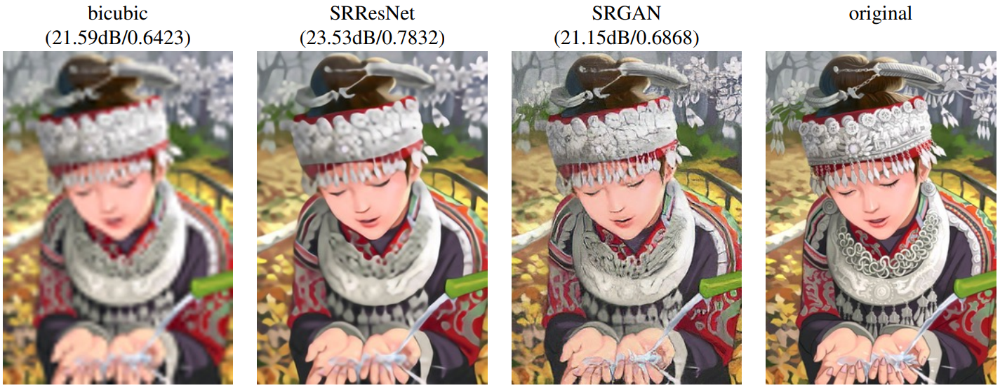

#### <b>(이론) SRGAN의 기여점(Contribution)</b>

* 본 논문에서는 PSNR의 한계점을 지적합니다.
    * MSE는 pixel-wise 방식으로 이미지 간 차이를 줄이므로, 지각적으로 관련있는 차이를 잡기 어렵습니다.
* 본 논문에서는 우수한 성능의 두 가지 네트워크를 제안합니다.
1. <b>SRResNet</b>: ResNet 기반으로 MSE를 줄인다는 점에서 <b>PSNR를 높이기 수월</b>합니다.
    * 이전까지 제안되었던 SOTA 모델에 비하여 실제로 PSNR, SSIM 상으로 우수합니다.
    * 하지만 MSE 기반의 솔루션은 과하게 smooth한 결과가 나오는 문제가 있습니다.
2. <b>SRGAN</b>: GAN을 활용하여 지각적으로 그럴싸한 고해상도 이미지를 만들 수 있습니다.
    * 자연 이미지의 manifold를 학습한다는 점에서 설득력 있는 솔루션을 만들 수 있습니다.
    * 사람이 직접 평가하는 MOS를 기준으로 가장 우수한 성능을 보입니다.

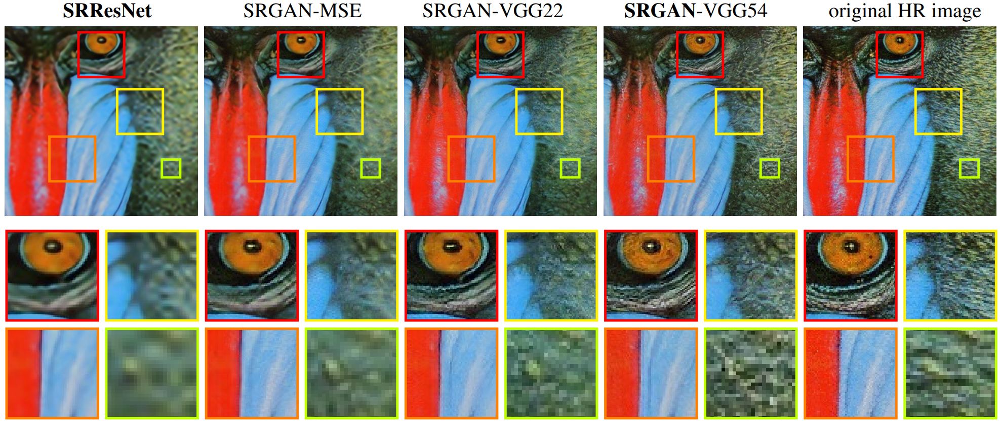

* <b>MOS (Mean Opinion Score)</b>를 수행한 결과 SRGAN이 이전까지의 다른 SOTA에 비해 뛰어난 성능을 보입니다.
    * MOS: 사람에게 직접 물어본 뒤에 1(bad quality)부터 5(excellent quality)까지의 점수를 매기도록 합니다.

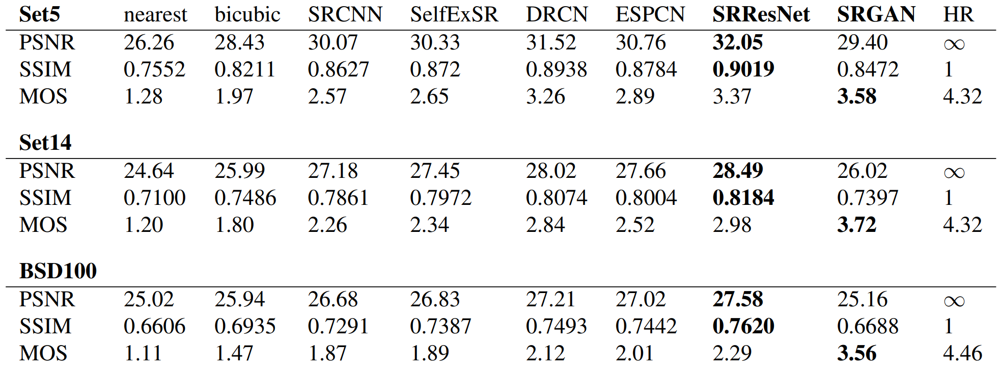

#### <b>(이론) Adversarial Network Architecture</b>

* <b>판별자(discriminator)</b>는 진짜 및 가짜 고해상도 이미지를 판별하도록 학습합니다.
* <b>생성자(generator)</b>는 만들어낸 가짜 고해상도 이미지가 판별자를 속이도록 학습합니다.
    * 결과적으로 가짜 고해상도 이미지는 판별자를 속일 수 있을 정도로, 진짜 이미지와 유사한 형태를 띠게 됩니다.

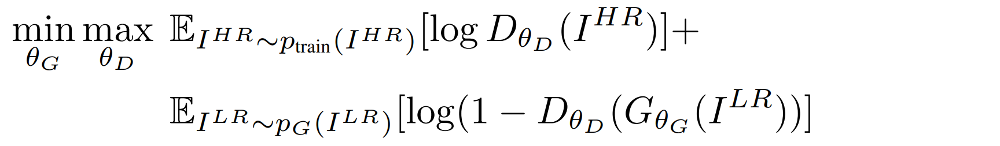

* 생성자(generator) 및 판별자(discriminator) 아키텍처는 다음과 같습니다.
    * 커널 크기(kernel size) *k*, 특징 맵의 개수(number of feature maps) *n*, 스트라이드(stride) *s*

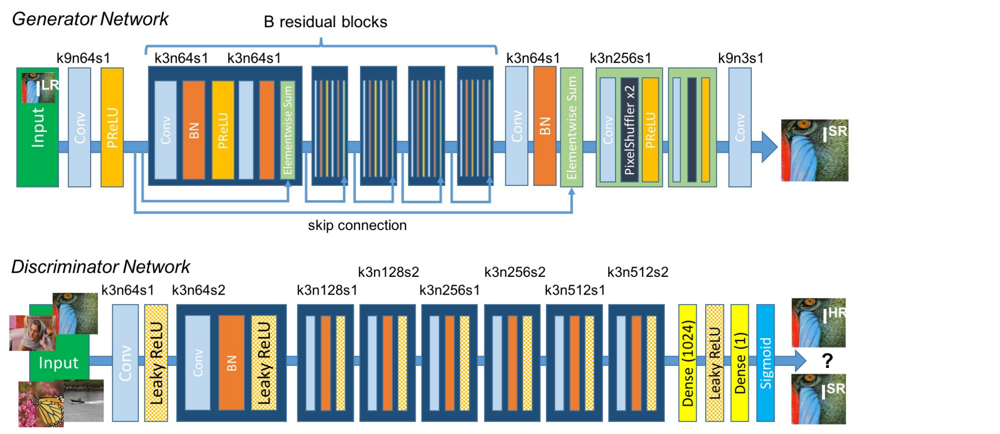

#### <b>(이론) 목적 함수(Objective Function)</b>

* SRGAN은 다음과 같은 목적 함수(object function)를 제안합니다.
* <b>지각 손실(perceptual loss)</b> = content loss + adversarial loss

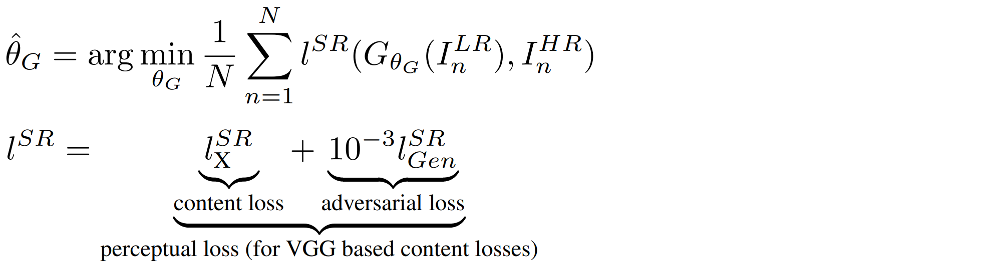

1. <b>VGG-based Content Loss</b>
    * 사전 학습된(pre-trained) 19 레이어 VGG 네트워크를 사용합니다.
    * 특정한(i번째 maxpooling 레이어 이전의 j번째 convolution) 출력 특징 맵(feature map) 상의 MSE를 계산합니다.
    * 결과적으로 VGG 네트워크의 high-level feature maps를 활용합니다.

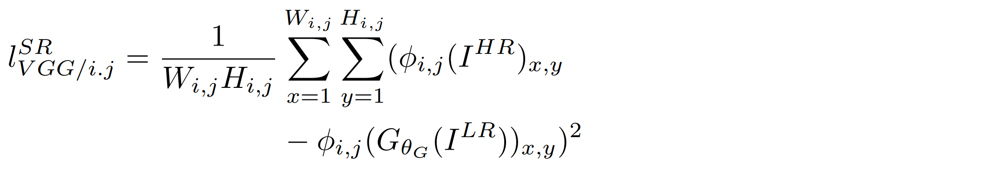

2. <b>Generative Loss</b>
    * 생성자가 만든 가짜 고해상도 이미지가 판별자(discriminator)를 속이도록 학습합니다.
    * 더 좋은 기울기(gradient)를 얻기 위해 다음과 같은 손실(loss)을 사용합니다.

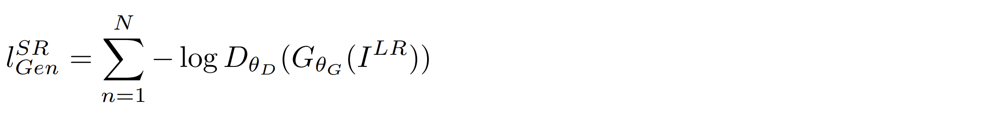

## <b>Step 2. SRGAN을 활용한 초해상도(Super-Resolution) 실습</b>

#### <b>핵심 아이디어 설명</b>

* SRGAN을 이용해 Scene Classification Dataset으로 모델을 학습합니다.
    * 원래 데이터셋은 레이블(label) 정보를 가지고 있지만, 본 실습에서는 레이블 정보는 활용하지 않습니다.
    * 전체 학습 과정을 이해할 수 있습니다.

#### <b>문제 1. 학습용 데이터셋 다운로드</b>

* 장면(scene) 데이터셋은 다양한 자연 경치(scene) 이미지로 구성된 데이터셋입니다.
    * 24,335개의 이미지로 구성됩니다.
    * 각 이미지는 150 X 150 크기를 가집니다.
    * 총 6개의 클래스(class)로 구성됩니다.
        0. 빌딩(buildings)
        1. 숲(forests)
        2. 빙하(glacier)
        3. 산(mountains)
        4. 바다(sea)
        5. 거리(street)
* 다양한 경로에서 데이터셋을 다운로드할 수 있습니다.
    * [사용 가능한 공식 Kaggle 데이터셋 경로](https://www.kaggle.com/nitishabharathi/scene-classification)
    * [사용 가능한 GitHub 저장소 경로(강의용)](https://github.com/ndb796/Scene-Classification-Dataset)
    * [사용 가능한 Onedrive 경로(강의용)](https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/EdVN-26VKHtMlm-uIkbTW20B5J-s6VXWIWYvefaDq3TtYQ?e=cpyoaB)

* ./scene_classification.zip을 다운로드한 뒤에 다음과 같이 압축을 해제합니다.

<pre>
데이터셋 경로/
    train-scene classification/
        train/ # 전체 이미지가 담긴 폴더입니다.
            0.jpg
            1.jpg
            2.jpg
            ...
            24333.jpg
            24334.jpg
        train.csv # 학습 이미지마다 클래스(class) 정보가 포함되어 있습니다.
    test_WyRytb0.csv # 최종 테스트(test) 이미지의 번호를 포함하며, 본 실습에서 사용하지 않습니다.
</pre>

In [1]:
# 깃허브에서 데이터셋 다운로드하기
!git clone https://github.com/ndb796/Scene-Classification-Dataset
# 폴더 안으로 이동
%cd Scene-Classification-Dataset

Cloning into 'Scene-Classification-Dataset'...
remote: Enumerating objects: 24303, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 24303 (delta 0), reused 6 (delta 0), pack-reused 24297
Receiving objects: 100% (24303/24303), 364.74 MiB | 18.69 MiB/s, done.
Resolving deltas: 100% (40/40), done.
Checking out files: 100% (24341/24341), done.
/content/Scene-Classification-Dataset


In [2]:
# 전체 학습 이미지 개수 세기
!ls './train-scene classification/train' -l | grep ^- | wc -l

24335


#### <b>문제 2. VGG 특징 추출기(Feature Extractor) 구현하기</b>

* <b>사전 학습된(pre-trained)</b> VGG 네트워크를 이용해 특징을 추출합니다.
    * 특정한 레이어까지의 출력 <b>특징 맵(feature map)을 반환</b>합니다.
* 다음과 같은 코드로 VGG 네트워크의 전체 레이어를 확인할 수 있습니다.
<pre>
print(nn.Sequential(*list(vgg19(pretrained=True).features.children())[:100]))
</pre>
* VGG 네트워크는 작은 크기의 3 X 3 컨볼루션 필터(filter)를 이용합니다.
    * 참고(reference): [VGG 원본 논문](https://arxiv.org/abs/1409.1556)
    * SRGAN에서는 VGG-19 네트워크를 특징 추출을 위한 기본적인 네트워크로 사용합니다.

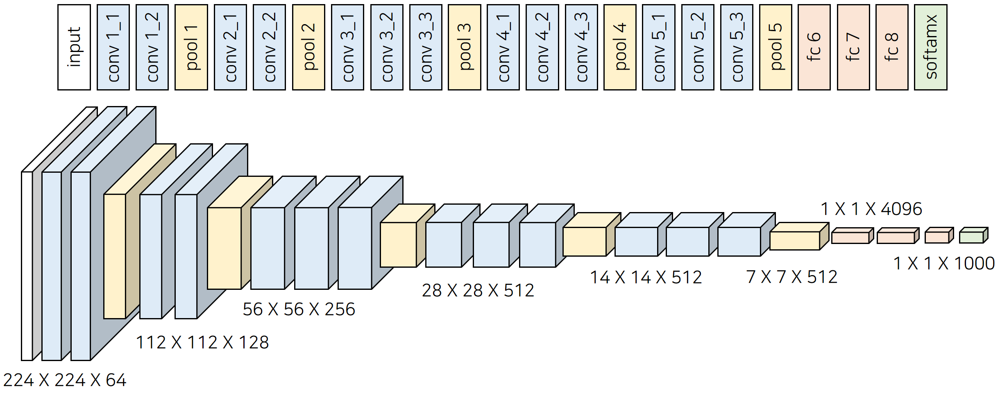

In [3]:
import torch.nn as nn
from torchvision.models import vgg19


class FeatureExtractor(nn.Module):
    def __init__(self):
        super(FeatureExtractor, self).__init__()
        self.feature_extractor = nn.Sequential(*list(vgg19(pretrained=True).features.children())[:18])
    
    def forward(self, img):
        return self.feature_extractor(img)

#### <b>문제 3. 잔여 블록(Residual Block) 구현하기</b>

* 생성자(generator)에 들어갈 잔여 블록(residual block)을 구현합니다.
* 잔여 블록(residual block) 구조는 다음과 같습니다.
    * 커널 크기(kernel size): 3 X 3
    * 스트라이드(stride): 1

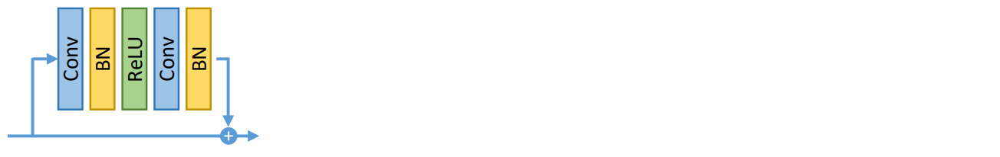

In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, in_features):
        super(ResidualBlock, self).__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(in_features, in_features, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(in_features, 0.8),
            nn.PReLU(),
            nn.Conv2d(in_features, in_features, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(in_features, 0.8),
        )
    
    def forward(self, x):
        return x + self.conv_block(x)

#### <b>문제 4. 생성자(Generator) 구현하기</b>

* 논문에서 제안한 아키텍처(architecture)를 최대한 그대로 구현합니다.
* 잔여 블록(residual block)을 활용합니다.

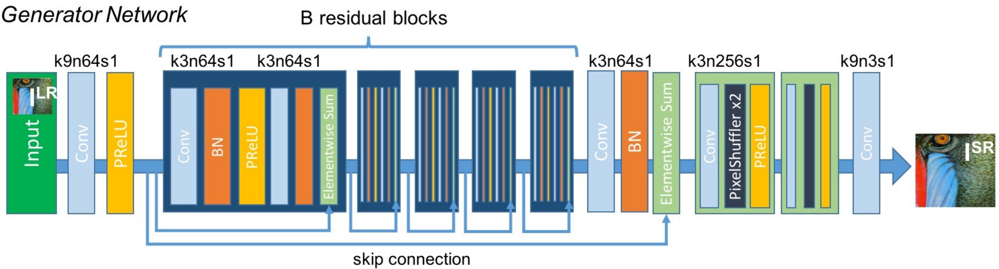

* 생성자 네트워크를 거치는 도중에 입력 이미지의 <b>너비와 높이가 4배씩 증가</b>합니다.
    * <b>PixelShuffle</b> 레이어가 업샘플링(upsampling)을 담당합니다.
    * 참고(reference): [ESPCN 논문](https://arxiv.org/abs/1609.05158)

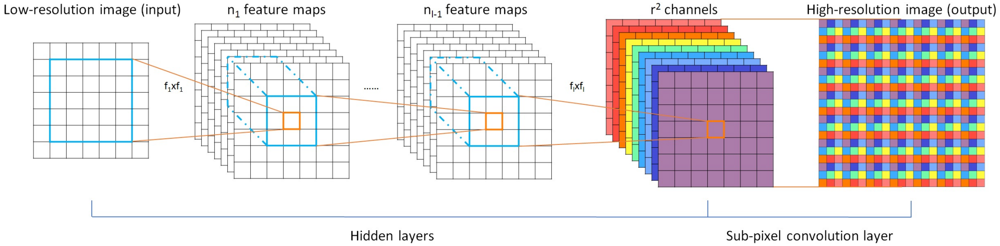

In [5]:
import torch


class GeneratorResNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, n_residual_blocks=16):
        super(GeneratorResNet, self).__init__()
        
        # First layer: k9n64s1 (출력: 64 X height X width)
        self.conv1 = nn.Sequential(nn.Conv2d(in_channels, 64, kernel_size=9, stride=1, padding=4), nn.PReLU())
    
        # Residual blocks: k3n64s1을 여러 번 반복 (출력: 64 X height X width)
        res_blocks = []
        for _ in range(n_residual_blocks):
            res_blocks.append(ResidualBlock(64))
        self.res_blocks = nn.Sequential(*res_blocks)

        # Second conv layer post residual blocks: k3n64s1 (출력: 64 X height X width)
        self.conv2 = nn.Sequential(nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64, 0.8))

        # Upsampling layers: k3n256s1을 2번 반복 (출력: 64 X height * 4 X width * 4)
        upsampling = []
        for _ in range(2):
            upsampling += [
                nn.Conv2d(64, 256, 3, 1, 1), # 채널 크기: 256
                nn.BatchNorm2d(256),
                nn.PixelShuffle(upscale_factor=2), # 업샘플링 과정에서 채널 크기 4배 감소
                nn.PReLU(),
            ]
        self.upsampling = nn.Sequential(*upsampling)

        # Final output layer: k9n3s1 (출력: 3 X height * 4 X width * 4)
        self.conv3 = nn.Sequential(nn.Conv2d(64, out_channels, kernel_size=9, stride=1, padding=4), nn.Tanh())

    def forward(self, x):
        out1 = self.conv1(x)
        out = self.res_blocks(out1)
        out2 = self.conv2(out)
        out = torch.add(out1, out2) # element-wise sum
        out = self.upsampling(out)
        out = self.conv3(out)
        return out

#### <b>문제 5. 판별자(Discriminator) 구현하기</b>

* 논문에서 제안한 아키텍처(architecture)를 최대한 그대로 구현합니다.
    * 일반적으로 사용되는 판별자(discriminator) 네트워크와 유사한 구조를 가지고 있습니다.
    * 깊은 콘볼루션 레이어로 갈수록 너비와 높이는 감소하고, 채널 수는 증가합니다.
* 총 4번에 걸쳐 다운샘플링(downsampling)을 진행합니다.
    * 결과적으로 특정한 이미지가 진짜(real)인지 가짜(fake)인지 판별합니다.

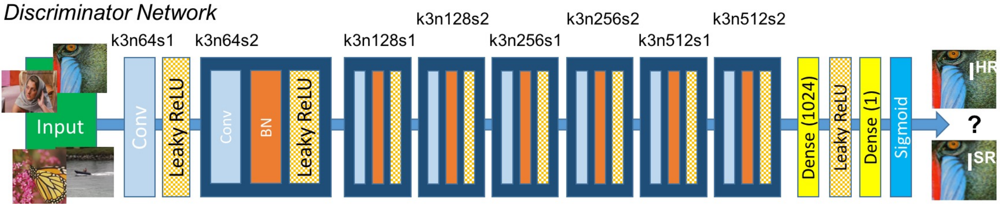

In [14]:
class Discriminator(nn.Module):
    def __init__(self, input_shape):
        super(Discriminator, self).__init__()

        self.input_shape = input_shape
        in_channels, in_height, in_width = self.input_shape
        patch_h, patch_w = int(in_height / (2 ** 4)), int(in_width / (2 ** 4))
        self.output_shape = (1, patch_h, patch_w)

        # 하나의 판별자(discriminator) 블록이 그림에서의 2개의 블록을 포함합니다.
        def discriminator_block(in_filters, out_filters, first_block=False):
            layers = []
            # 첫 번째 블록(block)
            layers.append(nn.Conv2d(in_filters, out_filters, kernel_size=3, stride=1, padding=1))
            if not first_block:
                layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            # 두 번째 블록(block)에서는 너비와 높이를 2배씩 감소시킵니다.
            layers.append(nn.Conv2d(out_filters, out_filters, kernel_size=3, stride=2, padding=1))
            layers.append(nn.BatchNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        layers = []
        in_filters = in_channels
        for i, out_filters in enumerate([64, 128, 256, 512]): # 출력 채널의 크기: 64 → 128 → 256 → 512
            layers.extend(discriminator_block(in_filters, out_filters, first_block=(i == 0)))
            in_filters = out_filters
        
        # 단순히 출력 채널 크기만 1로 변경(Fake와 Real 판단할 때 dimension이 1이 아니어도 상관 없음)
        layers.append(nn.Conv2d(out_filters, 1, kernel_size=3, stride=1, padding=1))
        self.model = nn.Sequential(*layers)

    def forward(self, img):
        return self.model(img)

#### <b>문제 6. 이미지 데이터셋 클래스 구현하기</b>

* 특정한 폴더에 존재하는 이미지를 불러오는 클래스(class)를 구현합니다.
* 이미지를 하나씩 불러와 (저해상도, 고해상도) 형태로 학습 데이터를 구성합니다.

In [15]:
import glob
import numpy as np
from PIL import Image

from torch.utils.data import Dataset
import torchvision.transforms as transforms

# 정규화(normalization) 파라미터(parameters) for pre-trained PyTorch models
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])


# 흑백 이미지를 RGB 색상 이미지로 변환
def to_rgb(image):
    rgb_image = Image.new("RGB", image.size)
    rgb_image.paste(image)
    return rgb_image


class ImageDataset(Dataset):
    def __init__(self, root, hr_shape):
        hr_height, hr_width = hr_shape
        # 저해상도(low resolution) 이미지를 만드는 변환(transform) 객체
        self.lr_transform = transforms.Compose(
            [
                transforms.Resize((hr_height // 4, hr_height // 4), Image.BICUBIC),
                transforms.ToTensor(),
                transforms.Normalize(mean, std),
            ]
        )
        # 고해상도(high resolution) 이미지를 만드는 변환(transform) 객체
        self.hr_transform = transforms.Compose(
            [
                transforms.Resize((hr_height, hr_height), Image.BICUBIC),
                transforms.ToTensor(),
                transforms.Normalize(mean, std),
            ]
        )

        # root 경로에 있는 전체 파일 경로를 계산합니다.
        self.files = sorted(glob.glob(root + '/*.*'))
    
    def __getitem__(self, index):
        img = Image.open(self.files[index % len(self.files)])

        # 흑백(grayscale) 이미지를 색상 이미지로 변환
        if img.mode != 'RGB':
            img = to_rgb(img)
        
        img_lr = self.lr_transform(img) # 저해상도(low resolution) 이미지
        img_hr = self.hr_transform(img) # 고해상도(high resolution) 이미지

        return {"lr": img_lr, "hr": img_hr}
    
    def __len__(self):
        return len(self.files)

#### <b>문제 7. 학습을 위한 하이퍼 파라미터 구성하기</b>

* [SRGAN PyTorch 구현 예시](https://github.com/eriklindernoren/PyTorch-GAN/blob/master/implementations/srgan/srgan.py)
    * 본 실습에서는 이미지의 크기가 150 X 150 해상도이므로, 2의 제곱 형태인 128 X 128로 변형하여 사용합니다.
* <b>epoch</b>: 현재 실행에서 학습을 재개할 에폭(epoch)
* <b>n_epochs</b>: 학습을 위한 총 에폭(epoch)
* <b>dataset_name</b>: 학습할 이미지가 포함된 폴더명
* <b>batch_size</b>: 배치 크기(batch size)
* <b>lr</b>: Adam 최적화를 위한 학습률(learning rate)
* <b>b1</b>: Adam을 위한 파라미터
* <b>b2</b>: Adam을 위한 파라미터
* <b>decay_epoch</b>: 학습률(learning rate) decay를 시작할 에폭(epoch)
* <b>n_cpu</b>: CPU 쓰레드(thread) 수
* <b>hr_height</b>: 고해상도(high resolution) 이미지의 높이(height)
* <b>hr_width</b>: 고해상도(high resolution) 이미지의 너비(width)
* <b>channels</b>: 이미지의 채널(channel) 크기
* <b>sample_interval</b>: 이미지를 저장할 배치 간격(interval)


In [16]:
import os
from types import SimpleNamespace


os.makedirs("images", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

opt = SimpleNamespace()
opt.epoch = 0 # 현재 실행에서 학습을 재개할 에폭(epoch)
opt.n_epochs = 200 # 학습을 위한 총 에폭(epoch)
opt.dataset_name = 'train-scene classification/train' # 학습할 이미지가 포함된 폴더명
opt.batch_size = 4 # 배치 크기(batch size)
opt.lr = 0.0002 # Adam 최적화를 위한 학습률(learning rate)
opt.b1 = 0.5 # Adam을 위한 파라미터
opt.b2 = 0.999 # Adam을 위한 파라미터
opt.decay_epoch = 100 # 학습률(learning rate) decay를 시작할 에폭(epoch)
opt.n_cpu = 4 # CPU 쓰레드(thread) 수
opt.hr_height = 128 # 고해상도(high resolution) 이미지의 높이(height)
opt.hr_width = 128 # 고해상도(high resolution) 이미지의 너비(width)
opt.channels = 3 # 이미지의 채널(channel) 크기
opt.sample_interval = 100 # 이미지를 저장할 배치 간격(interval)
print(opt)

namespace(b1=0.5, b2=0.999, batch_size=4, channels=3, dataset_name='train-scene classification/train', decay_epoch=100, epoch=0, hr_height=128, hr_width=128, lr=0.0002, n_cpu=4, n_epochs=200, sample_interval=100)


#### <b>문제 8. 네트워크 객체 초기화</b>

* 세 가지 네트워크를 초기화합니다.
    * 특징 추출기(feature extractor): <b>사전 학습된(pre-trained)</b> VGG 네트워크를 사용합니다.
    * 생성자(generator): 본 실습에서 학습을 진행합니다.
    * 판별자(discriminator): 본 실습에서 학습을 진행합니다.
* 손실(loss) 객체를 정의합니다.
    * GAN 손실(adversarial loss) = MSE 손실
    * 콘텐츠 손실(content loss) = L1 손실

In [19]:
cuda = torch.cuda.is_available()
hr_shape = (opt.hr_height, opt.hr_width)

# 생성자(generator) 및 판별자(discriminator) 초기화
generator = GeneratorResNet()
discriminator = Discriminator(input_shape=(opt.channels, *hr_shape))

# 특징 추출기를 초기화하고 추론(inference) 모드로 변경합니다.
feature_extractor = FeatureExtractor()
feature_extractor.eval()

# 손실 함수(loss function)
criterion_GAN = torch.nn.MSELoss()
criterion_content = torch.nn.L1Loss()

# GPU 기기로 옮기기
if cuda:
    generator = generator.cuda()
    discriminator = discriminator.cuda()
    feature_extractor = feature_extractor.cuda()
    criterion_GAN = criterion_GAN.cuda()
    criterion_content = criterion_content.cuda()

# optimizers 초기화
optimizer_G = torch.optim.Adam(generator.parameters(), lr=opt.lr, betas=(opt.b1, opt.b2))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=opt.lr, betas=(opt.b1, opt.b2))

#### <b>문제 9. 네트워크 학습 진행하기</b>

* SRGAN 네트워크의 학습을 진행합니다.

In [ ]:
import time

from torchvision.utils import save_image, make_grid
from torch.utils.data import DataLoader
from torch.autograd import Variable


Tensor = torch.cuda.FloatTensor if cuda else torch.Tensor

dataloader = DataLoader(
    ImageDataset("./%s" % opt.dataset_name, hr_shape=hr_shape),
    batch_size=opt.batch_size,
    shuffle=True,
    num_workers=opt.n_cpu,
)

start_time = time.time() # 시작 시간

for epoch in range(opt.epoch, opt.n_epochs):
    for i, imgs in enumerate(dataloader):

        # 모델 입력에 대하여 설정을 진행합니다.
        imgs_lr = Variable(imgs["lr"].type(Tensor))
        imgs_hr = Variable(imgs["hr"].type(Tensor))

        # 판별자(discriminator)에 들어갈 ground-truths
        valid = Variable(Tensor(np.ones((imgs_lr.size(0), *discriminator.output_shape))), requires_grad=False)
        fake = Variable(Tensor(np.zeros((imgs_lr.size(0), *discriminator.output_shape))), requires_grad=False)

        # -----------------------------------
        # 생성자(generator) 학습하기
        # -----------------------------------

        optimizer_G.zero_grad()

        # 저해상도(low resolution) 이미지로 고해상도(high resolution) 이미지 생성
        gen_hr = generator(imgs_lr)

        # Adversarial loss
        loss_GAN = criterion_GAN(discriminator(gen_hr), valid)

        # Content loss
        gen_features = feature_extractor(gen_hr)
        real_features = feature_extractor(imgs_hr)
        loss_content = criterion_content(gen_features, real_features.detach())

        # Total loss
        loss_G = loss_content + 1e-3 * loss_GAN

        loss_G.backward()
        optimizer_G.step()

        # -----------------------------------
        # 판별자(discriminator) 학습하기
        # -----------------------------------

        optimizer_D.zero_grad()

        # Loss of real and fake images
        loss_real = criterion_GAN(discriminator(imgs_hr), valid)
        loss_fake = criterion_GAN(discriminator(gen_hr.detach()), fake)

        # Total loss
        loss_D = (loss_real + loss_fake) / 2

        loss_D.backward()
        optimizer_D.step()

        # -----------------------------------
        # 로깅(logging)
        # -----------------------------------

        batches_done = epoch * len(dataloader) + i
        if batches_done % opt.sample_interval == 0:
            # Save image grid with upsampled inputs and SRGAN outputs
            imgs_lr = nn.functional.interpolate(imgs_lr, scale_factor=4)
            gen_hr = make_grid(gen_hr, nrow=1, normalize=True)
            imgs_lr = make_grid(imgs_lr, nrow=1, normalize=True)
            img_grid = torch.cat((imgs_lr, gen_hr), -1)
            save_image(img_grid, "images/%d.png" % batches_done, normalize=False)
            print('[Epoch %d/%d] [Batch %d/%d] [D loss: %f] [G loss: %f] [Time elapsed (seconds): %f]' %
                  (epoch, opt.n_epochs, i, len(dataloader), loss_D.item(), loss_G.item(), time.time() - start_time))
            # Save model checkpoints
            torch.save(generator.state_dict(), "saved_models/generator_%d_latest.pth" % epoch)
            torch.save(discriminator.state_dict(), "saved_models/discriminator_%d_latest.pth" % epoch)

* 학습된 네트워크 불러오기
    * [12 epoch까지 학습된 생성자](https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/EcjsEUG4KuNLjc8lH0PwxNAByIgHVABPdW-WKPwliTSXFA)
    * [12 epoch까지 학습된 판별자](https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/Ec6t7IAKeVRDvbtSX59mgCwByQzlzmGTezXjJ3Wa9siQLw)

In [21]:
!wget https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/EcjsEUG4KuNLjc8lH0PwxNAByIgHVABPdW-WKPwliTSXFA?download=1 -O generator_12_latest.pth
!wget https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/Ec6t7IAKeVRDvbtSX59mgCwByQzlzmGTezXjJ3Wa9siQLw?download=1 -O discriminator_12_latest.pth

--2021-06-23 00:15:32--  https://postechackr-my.sharepoint.com/:u:/g/personal/dongbinna_postech_ac_kr/EcjsEUG4KuNLjc8lH0PwxNAByIgHVABPdW-WKPwliTSXFA?download=1
Resolving postechackr-my.sharepoint.com (postechackr-my.sharepoint.com)... 13.107.136.9
Connecting to postechackr-my.sharepoint.com (postechackr-my.sharepoint.com)|13.107.136.9|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: /personal/dongbinna_postech_ac_kr/Documents/%eb%94%a5%eb%9f%ac%eb%8b%9d%20300%ec%a0%9c%20%ea%b0%95%ec%9d%98%20%ec%b4%ac%ec%98%81%eb%b3%b8/%ed%95%99%ec%8a%b5%eb%90%9c%20%eb%aa%a8%eb%8d%b8%20%ed%8c%8c%ec%9d%bc/generator_12_latest.pth?originalPath=aHR0cHM6Ly9wb3N0ZWNoYWNrci1teS5zaGFyZXBvaW50LmNvbS86dTovZy9wZXJzb25hbC9kb25nYmlubmFfcG9zdGVjaF9hY19rci9FY2pzRVVHNEt1TkxqYzhsSDBQd3hOQUJ5SWdIVkFCUGRXLVdLUHdsaVRTWEZBP3J0aW1lPVBXU0dCTncxMlVn [following]
--2021-06-23 00:15:33--  https://postechackr-my.sharepoint.com/personal/dongbinna_postech_ac_kr/Documents/%eb%94%a5%eb%9f%ac%eb%8b%9d%2030

In [69]:
cuda = torch.cuda.is_available()
hr_shape = (opt.hr_height, opt.hr_width)

# 생성자(generator) 및 판별자(discriminator) 초기화
generator = GeneratorResNet()
discriminator = Discriminator(input_shape=(opt.channels, *hr_shape))

# GPU 기기로 옮기기
if cuda:
    generator = generator.cuda()
    discriminator = discriminator.cuda()

# 사전 학습된(pre-trained) 모델 불러오기
generator.load_state_dict(torch.load("generator_12_latest.pth"))
discriminator.load_state_dict(torch.load("discriminator_12_latest.pth"))

<All keys matched successfully>

* 내가 가지고 있는 이미지로 해상도 개선해보기

/usr/local/lib/python3.7/dist-packages/torchvision/transforms/transforms.py:281: UserWarning: Argument interpolation should be of type InterpolationMode instead of int. Please, use InterpolationMode enum.
  "Argument interpolation should be of type InterpolationMode instead of int. "


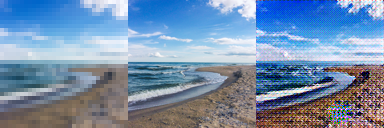

In [77]:
from IPython.display import Image as Display # to display images


# 저해상도(low resolution) 이미지를 만드는 변환(transform) 객체
lr_transform = transforms.Compose(
    [
        transforms.Resize((opt.hr_height // 4, opt.hr_height // 4), Image.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)
# 고해상도(high resolution) 이미지를 만드는 변환(transform) 객체
hr_transform = transforms.Compose(
    [
        transforms.Resize((opt.hr_height, opt.hr_height), Image.BICUBIC),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ]
)

image = Image.open('custom_images/2.jpg')
lr_image = lr_transform(image).unsqueeze(0).cuda()
hr_image = hr_transform(image).unsqueeze(0).cuda()
hr_generated = generator(lr_image)

# Save image grid with upsampled inputs and SRGAN outputs
lr_image = nn.functional.interpolate(lr_image, scale_factor=4)
lr_image = make_grid(lr_image, nrow=1, normalize=True)
hr_image = make_grid(hr_image, nrow=1, normalize=True)
hr_generated = make_grid(hr_generated, nrow=1, normalize=True)
img_grid = torch.cat((lr_image, hr_image, hr_generated), -1)
save_image(img_grid, "result.png", normalize=False)

# 결과 이미지를 출력해보기
# 차례대로 [저해상도, 고해상도, 해상도 복원 결과]입니다.
Display(filename='result.png')